In [ ]:
import os, time, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from tensorflow import keras
from sklearn.metrics import (classification_report, confusion_matrix, precision_recall_fscore_support, roc_auc_score)
from sklearn.preprocessing import label_binarize
warnings.filterwarnings("ignore")



In [ ]:
train_file = "CICIOT23/train/train.csv"
val_file   = "CICIOT23/validation/validation.csv"
test_file  = "CICIOT23/test/test.csv"
W6_DIR  = "outputs_week6"      # produced by Week 6
OUT_DIR = "outputs_week7"; os.makedirs(OUT_DIR, exist_ok=True)
EDA_SAMPLE = 300_000           

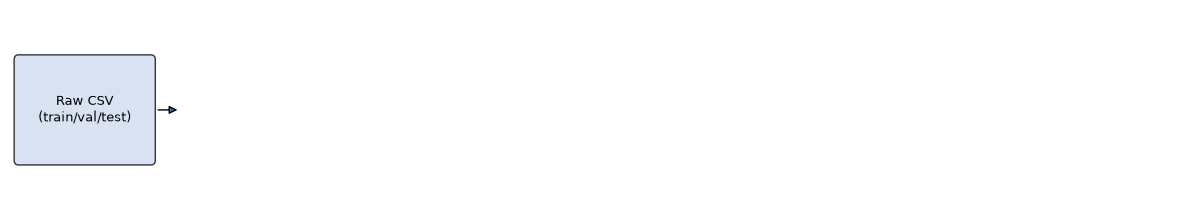

In [5]:
# Simple pipeline diagram
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
steps = ["Raw CSV\n(train/val/test)", "Load\nfloat32 chunks", "Label grouping\n34 → 8", "Pre-process\nlog1p + scale",
         "Class\nweights", "Train\nMLP / 1D-CNN", "Evaluate\nP/R/F1/AUC"]
fig, ax = plt.subplots(figsize=(15, 2.6)); ax.axis("off"); ax.set_xlim(0, len(steps)*2); ax.set_ylim(0, 2)
for i, s in enumerate(steps):
    ax.add_patch(FancyBboxPatch((i*2+.1, .5), 1.6, 1, boxstyle="round,pad=0.05", fc="#D9E2F3", ec="#333"))
    ax.text(i*2+.9, 1, s, ha="center", va="center", fontsize=9)
    if i < len(steps)-1:
        ax.add_patch(FancyArrowPatch((i*2+1.75, 1), (i*2+2.05, 1), arrowstyle="-|>", mutation_scale=12)); plt.show()

In [6]:
# Class counts over the FULL files, reading only the label column (memory-friendly)
def label_counts(path):
    vc = None
    for ch in pd.read_csv(path, usecols=["label"], chunksize=500_000):
        v = ch.label.value_counts(); vc = v if vc is None else vc.add(v, fill_value=0)
    return vc.astype(int).sort_values(ascending=False)

counts = pd.DataFrame({"train": label_counts(train_file), "validation": label_counts(val_file), "test": label_counts(test_file)})
print("Rows:", counts.sum().to_dict(), "| classes:", len(counts))
counts.to_csv(f"{OUT_DIR}/class_counts.csv"); counts

Rows: {'train': 5491971, 'validation': 1176851, 'test': 1176851} | classes: 34


,train,validation,test
label,,,
Backdoor_Malware,392,93,89
BenignTraffic,129538,27519,27709
BrowserHijacking,665,158,134
CommandInjection,620,132,119
DDoS-ACK_Fragmentation,33581,7194,7292
DDoS-HTTP_Flood,3371,706,709
DDoS-ICMP_Flood,848088,182011,180447
DDoS-ICMP_Fragmentation,53046,11430,11402
DDoS-PSHACK_Flood,481254,102985,103326


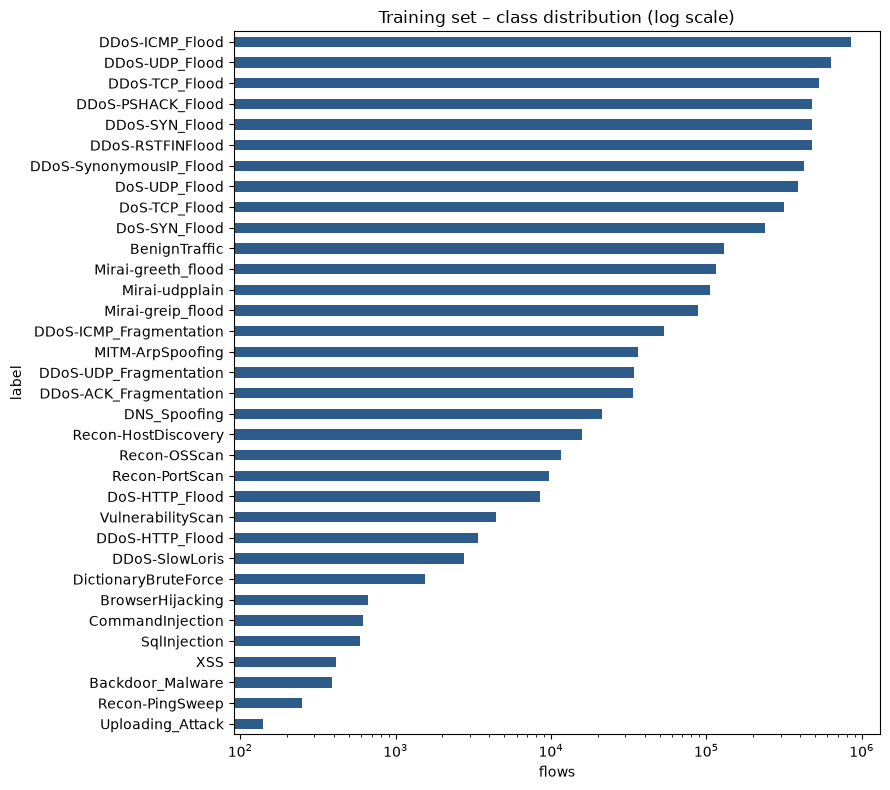

Imbalance ratio (max/min): 6058


In [7]:
ax = counts["train"].sort_values().plot(kind="barh", figsize=(9, 8), logx=True, color="#2E5C8A")
ax.set_title("Training set – class distribution (log scale)"); ax.set_xlabel("flows")
plt.tight_layout();  plt.show()
print("Imbalance ratio (max/min):", round(counts.train.max()/counts.train.min()))

In [8]:
# Load a random sample of the training file for feature-level EDA
def load_sample(path, n, chunksize=500_000, seed=42):
    header = pd.read_csv(path, nrows=0).columns
    dt = {c: "float32" for c in header if c != "label"}
    total = counts["train"].sum(); frac = min(1.0, n/total)
    return pd.concat([c.sample(frac=frac, random_state=seed) for c in pd.read_csv(path, dtype=dt, chunksize=chunksize)],
                     ignore_index=True)
eda = load_sample(train_file, EDA_SAMPLE)
print(eda.shape, "| missing values:", int(eda.isna().sum().sum()), "| duplicates:", int(eda.duplicated().sum()))
eda.head()

(300004, 47) | missing values: 0 | duplicates: 13650


,flow_duration,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,label
0,0.000000,54.080002,6.00,67.820000,2.667762,2.667762,0.0,0.0,0.0,0.0,...,0.218252,54.080002,83071568.0,9.5,10.401771,0.309044,0.323113,0.15,141.550003,DDoS-TCP_Flood
1,0.000000,53.459999,5.94,63.360001,2.863916,2.863916,0.0,0.0,0.0,0.0,...,0.013077,54.060001,83331040.0,9.5,10.392304,0.000000,0.000000,0.00,141.550003,DDoS-PSHACK_Flood
2,0.000000,0.000000,1.00,64.000000,73.618507,73.618507,0.0,0.0,0.0,0.0,...,0.000000,42.000000,83150328.0,9.5,9.165152,0.000000,0.000000,0.00,141.550003,DDoS-ICMP_Flood
3,0.168951,25395.000000,17.00,64.000000,6754.834473,6754.834473,0.0,0.0,0.0,0.0,...,0.000000,50.000000,83106168.0,9.5,10.000000,0.000000,0.000000,0.00,141.550003,DDoS-UDP_Flood
4,0.000000,0.000000,1.00,64.000000,1.005389,1.005389,0.0,0.0,0.0,0.0,...,0.000000,42.000000,83127976.0,9.5,9.165152,0.000000,0.000000,0.00,141.550003,DDoS-ICMP_Flood


In [9]:
prep = joblib.load(f"{W6_DIR}/preprocessing.joblib")
classes, feature_cols, skewed, scaler, LABEL_MODE = (prep[k] for k in ("classes","feature_cols","skewed","scaler","label_mode"))
FAMILY = {"BenignTraffic":"Benign","MITM-ArpSpoofing":"Spoofing","DNS_Spoofing":"Spoofing","DictionaryBruteForce":"BruteForce",
 "Recon-HostDiscovery":"Recon","Recon-OSScan":"Recon","Recon-PortScan":"Recon","Recon-PingSweep":"Recon","VulnerabilityScan":"Recon",
 "BrowserHijacking":"Web","SqlInjection":"Web","CommandInjection":"Web","XSS":"Web","Backdoor_Malware":"Web","Uploading_Attack":"Web"}
def map_label(l):
    if LABEL_MODE == "34": return l
    if LABEL_MODE == "2":  return "Benign" if l == "BenignTraffic" else "Attack"
    if l in FAMILY: return FAMILY[l]
    for p in ("DDoS","DoS","Mirai"):
        if l.startswith(p): return p
    return l
eda["target"] = eda["label"].map(map_label)
print("Label mode:", LABEL_MODE); eda["target"].value_counts()

Label mode: 8


target
DDoS          218268
DoS            51697
Mirai          17110
Benign          7201
Spoofing        3215
Recon           2284
Web              148
BruteForce        81
Name: count, dtype: int64

In [10]:
all_feats = [c for c in eda.columns if c not in ("label","target")]
print("Constant columns:", [c for c in all_feats if eda[c].nunique() <= 1])
eda[all_feats].describe().T[["mean","std","min","50%","max"]].round(3)

Constant columns: ['cwr_flag_number', 'Telnet', 'SMTP', 'IRC', 'DHCP']


,mean,std,min,50%,max
flow_duration,5.759000e+00,2.975800e+02,0.000,0.000000e+00,6.835893e+04
Header_Length,7.777036e+04,4.597838e+05,0.000,5.400000e+01,9.679616e+06
Protocol Type,9.082000e+00,8.954000e+00,0.000,6.000000e+00,4.700000e+01
Duration,6.638000e+01,1.414000e+01,0.000,6.400000e+01,2.550000e+02
Rate,9.189093e+03,1.004685e+05,0.000,1.588700e+01,7.340032e+06
Srate,9.189093e+03,1.004685e+05,0.000,1.588700e+01,7.340032e+06
Drate,0.000000e+00,1.000000e-03,0.000,0.000000e+00,6.950000e-01
fin_flag_number,8.700000e-02,2.820000e-01,0.000,0.000000e+00,1.000000e+00
syn_flag_number,2.060000e-01,4.040000e-01,0.000,0.000000e+00,1.000000e+00
rst_flag_number,9.100000e-02,2.870000e-01,0.000,0.000000e+00,1.000000e+00


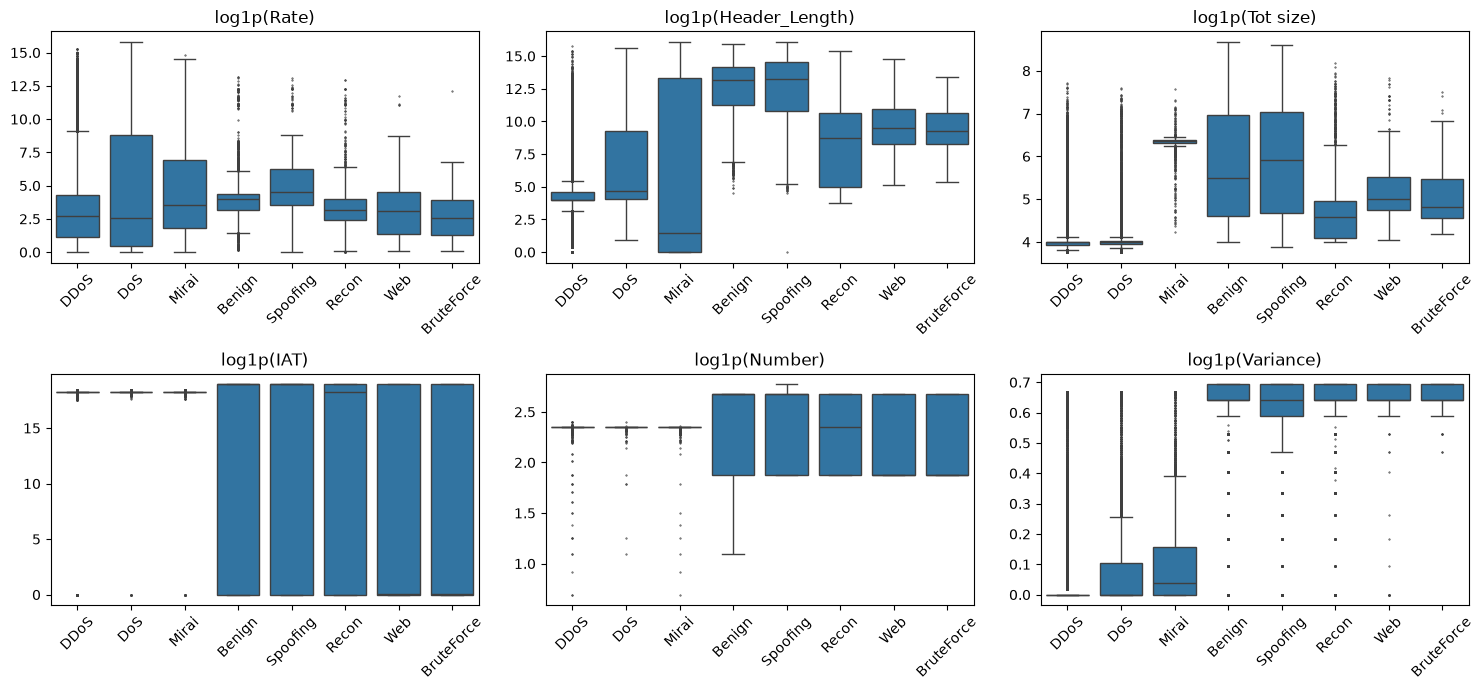

In [11]:
# Feature distributions by class (log1p) for a few informative features
sel = ["Rate", "Header_Length", "Tot size", "IAT", "Number", "Variance"]
order = list(eda["target"].value_counts().index)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, c in zip(axes.ravel(), sel):
    sns.boxplot(data=eda.assign(v=np.log1p(eda[c].clip(lower=0))), x="target", y="v", order=order, ax=ax, fliersize=.5)
    ax.set_title(f"log1p({c})"); ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(axis="x", rotation=45)
plt.tight_layout();  plt.show()

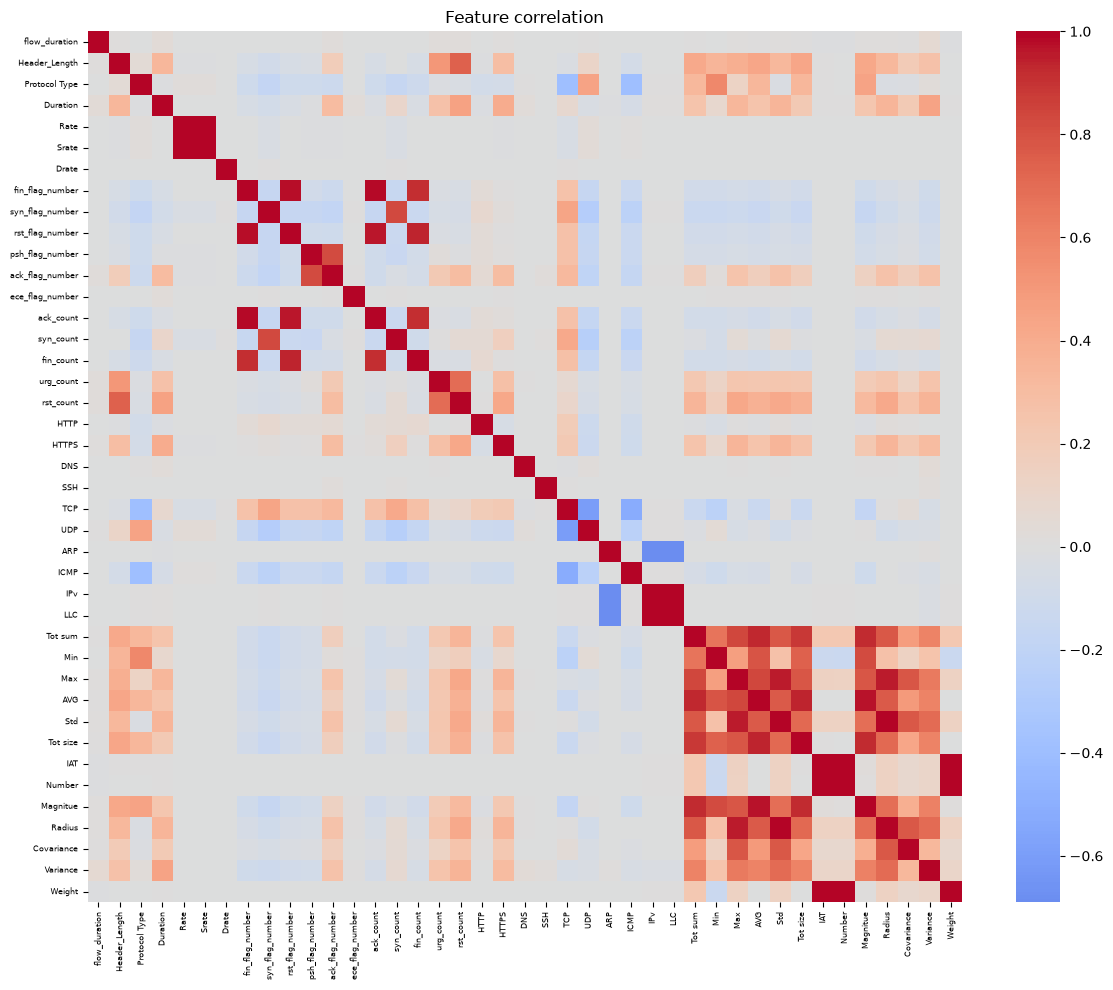

IPv              LLC                1.0000
Rate             Srate              1.0000
Std              Radius             1.0000
Number           Weight             0.9997
IAT              Weight             0.9978
                 Number             0.9967
fin_flag_number  ack_count          0.9864
                 rst_flag_number    0.9749
AVG              Magnitue           0.9675
rst_flag_number  ack_count          0.9620
dtype: float64

In [12]:
corr = eda[[c for c in all_feats if eda[c].nunique() > 1]].corr()
plt.figure(figsize=(12, 10)); sns.heatmap(corr, cmap="coolwarm", center=0, xticklabels=True, yticklabels=True)
plt.xticks(fontsize=6); plt.yticks(fontsize=6); plt.title("Feature correlation"); plt.tight_layout(); plt.show()
pairs = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().sort_values(ascending=False)
pairs.head(10).round(4)

In [13]:
# Step 1: encode labels
cls2id = {c: i for i, c in enumerate(classes)}
# Step 2: apply the SAME preprocessing used in Week 6
def prepare(df):
    X = df[feature_cols].copy()
    X[skewed] = np.log1p(X[skewed].clip(lower=0))
    return scaler.transform(X.values.astype("float32")).astype("float32")

print("Features kept:", len(feature_cols), "| log1p applied to:", len(skewed), "columns")
before = eda[skewed[:4]].describe().T[["mean","std","max"]]
after = pd.DataFrame(prepare(eda.head(50_000)), columns=feature_cols)[skewed[:4]].describe().T[["mean","std","max"]]
print("Before preprocessing:"); display(before.round(2)); print("After log1p + scaling:"); display(after.round(2))

Features kept: 42 | log1p applied to: 18 columns
Before preprocessing:


,mean,std,max
flow_duration,5.76,297.58,68358.93
Header_Length,77770.36,459783.81,9679616.00
Duration,66.38,14.14,255.00
Rate,9189.09,100468.52,7340032.00


After log1p + scaling:


,mean,std,max
flow_duration,-0.0,1.0,12.70
Header_Length,-0.0,1.0,3.02
Duration,0.0,1.0,10.37
Rate,0.0,1.0,3.76


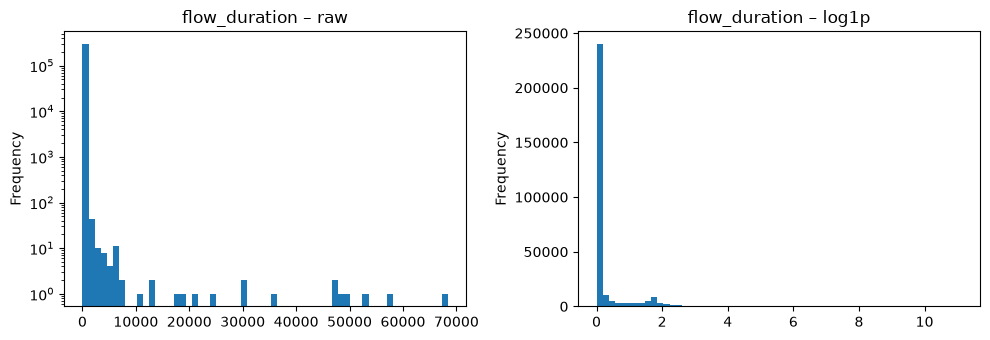

In [14]:
# Visual proof of the transform on one heavy-tailed feature
c = skewed[0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
eda[c].plot(kind="hist", bins=60, ax=ax[0], title=f"{c} – raw", logy=True)
np.log1p(eda[c].clip(lower=0)).plot(kind="hist", bins=60, ax=ax[1], title=f"{c} – log1p")
plt.tight_layout(); plt.show()

In [15]:
mlp = keras.models.load_model(f"{W6_DIR}/mlp.keras"); cnn = keras.models.load_model(f"{W6_DIR}/cnn1d.keras")
mlp.summary(); cnn.summary()
print("Parameters – MLP:", mlp.count_params(), "| 1D-CNN:", cnn.count_params())

Model: "MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        11,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161,114 (629.36 KB)

 Trainable params: 53,448 (208.78 KB)

 Non-trainable params: 768 (3.00 KB)

...

 Total params: 276,890 (1.06 MB)

 Trainable params: 92,168 (360.03 KB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 184,338 (720.07 KB)

Parameters – MLP: 54216 | 1D-CNN: 92552


In [16]:
def load_split(path):
    header = pd.read_csv(path, nrows=0).columns
    d = pd.read_csv(path, dtype={c: "float32" for c in header if c != "label"})
    y = d["label"].map(map_label).map(cls2id).values
    return prepare(d), y
X_test, y_test = load_split(test_file)
n_classes = len(classes); print(X_test.shape)

res, preds = [], {}
for name, m, X in [("MLP", mlp, X_test), ("1D-CNN", cnn, X_test[..., None])]:
    t0 = time.time(); proba = m.predict(X, batch_size=4096, verbose=0); inf = time.time() - t0
    pred = proba.argmax(1); preds[name] = (pred, proba)
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(y_test, pred, average="weighted", zero_division=0)
    present = np.unique(y_test)
    auc = roc_auc_score(label_binarize(y_test, classes=np.arange(n_classes))[:, present], proba[:, present], average="macro") \
          if n_classes > 2 else roc_auc_score(y_test, proba[:, 1])
    res.append(dict(model=name, accuracy=(pred == y_test).mean(), precision_macro=p, recall_macro=r, f1_macro=f,
                    f1_weighted=fw, auc_roc_macro=auc, inference_sec=inf, params=m.count_params()))
summary = pd.DataFrame(res).round(4); summary.to_csv(f"{OUT_DIR}/results_summary.csv", index=False); summary

(1176851, 42)


,model,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,auc_roc_macro,inference_sec,params
0,MLP,0.9013,0.7482,0.6525,0.6767,0.8980,0.9856,2.4816,54216
1,1D-CNN,0.9056,0.7176,0.6729,0.6883,0.9024,0.9868,16.2508,92552


,MLP_precision,MLP_recall,MLP_f1-score,1D-CNN_precision,1D-CNN_recall,1D-CNN_f1-score,support
Benign,0.840,0.918,0.877,0.842,0.926,0.882,27709.0
BruteForce,0.761,0.210,0.329,0.494,0.260,0.341,319.0
DDoS,0.922,0.957,0.939,0.924,0.961,0.942,855981.0
DoS,0.789,0.662,0.720,0.805,0.670,0.731,204245.0
Mirai,0.995,0.994,0.995,0.996,0.995,0.996,66749.0
Recon,0.667,0.654,0.661,0.661,0.700,0.680,8812.0
Spoofing,0.755,0.704,0.728,0.829,0.661,0.736,12410.0
Web,0.256,0.121,0.165,0.189,0.211,0.199,626.0


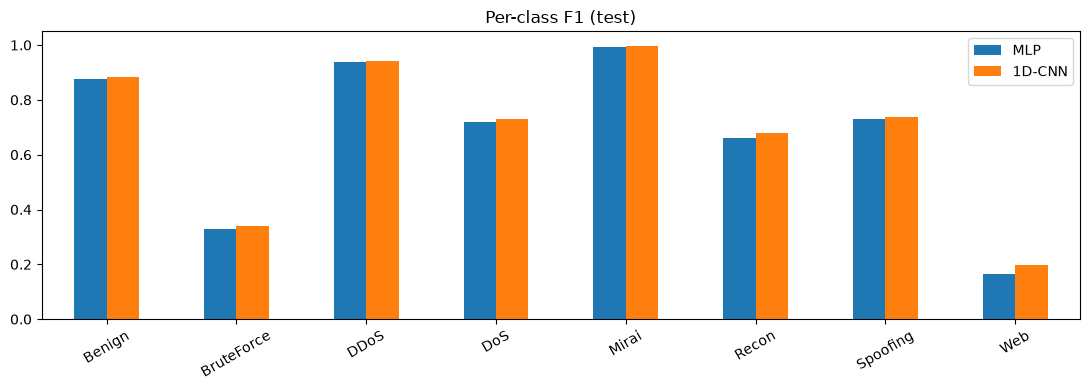

In [ ]:
# Per-class F1 comparison
rep = {n: pd.DataFrame(classification_report(y_test, p, labels=np.arange(n_classes), target_names=classes,
                       output_dict=True, zero_division=0)).T.iloc[:n_classes] for n, (p, _) in preds.items()}
perclass = pd.DataFrame({f"{n}_{m}": rep[n][m] for n in rep for m in ("precision", "recall", "f1-score")})
perclass["support"] = rep["MLP"]["support"]; perclass.round(4).to_csv(f"{OUT_DIR}/per_class_metrics.csv"); display(perclass.round(3))
ax = pd.DataFrame({n: rep[n]["f1-score"] for n in rep}).plot(kind="bar", figsize=(11, 4), rot=30)
ax.set_title("Per-class F1 (test)"); ax.set_ylim(0, 1.05); plt.tight_layout();  plt.show()

In [18]:
# Most common confusions (true -> predicted) for each model
for n, (pred, _) in preds.items():
    cm = confusion_matrix(y_test, pred, labels=np.arange(n_classes)); np.fill_diagonal(cm, 0)
    top = [(classes[i], classes[j], cm[i, j]) for i, j in zip(*np.unravel_index(np.argsort(cm, axis=None)[::-1][:8], cm.shape)) if cm[i, j] > 0]
    print(f"\n{n} – top confusions"); display(pd.DataFrame(top, columns=["true", "predicted", "count"]))


MLP – top confusions


,true,predicted,count
0,DoS,DDoS,68732
1,DDoS,DoS,36111
2,Spoofing,Benign,2804
3,Recon,Benign,1805
4,Benign,Spoofing,1308
5,Recon,Spoofing,1131
6,Benign,Recon,874
7,Spoofing,Recon,786



1D-CNN – top confusions


,true,predicted,count
0,DoS,DDoS,67214
1,DDoS,DoS,32995
2,Spoofing,Benign,2817
3,Recon,Benign,1774
4,Spoofing,Recon,1134
5,Benign,Recon,1002
6,Benign,Spoofing,848
7,Recon,Spoofing,645


In [19]:
# AUC vs recall per class: high AUC with low recall = the model ranks the class well but the argmax threshold misses it
Yb = label_binarize(y_test, classes=np.arange(n_classes)) if n_classes > 2 else None
rows = []
for n, (pred, proba) in preds.items():
    for i, c in enumerate(classes):
        if n_classes > 2 and Yb[:, i].sum() > 0:
            rows.append(dict(model=n, cls=c, auc=roc_auc_score(Yb[:, i], proba[:, i]), recall=rep[n].loc[c, "recall"]))
auc_rec = pd.DataFrame(rows); display(auc_rec.pivot(index="cls", columns="model", values=["auc", "recall"]).round(3))

auc        recall       
model      1D-CNN    MLP 1D-CNN    MLP
cls                                   
Benign      0.999  0.999  0.926  0.918
BruteForce  0.996  0.996  0.260  0.210
DDoS        0.961  0.958  0.961  0.957
DoS         0.947  0.941  0.670  0.662
Mirai       1.000  1.000  0.995  0.994
Recon       0.997  0.997  0.700  0.654
Spoofing    0.998  0.997  0.661  0.704
Web         0.997  0.997  0.211  0.121

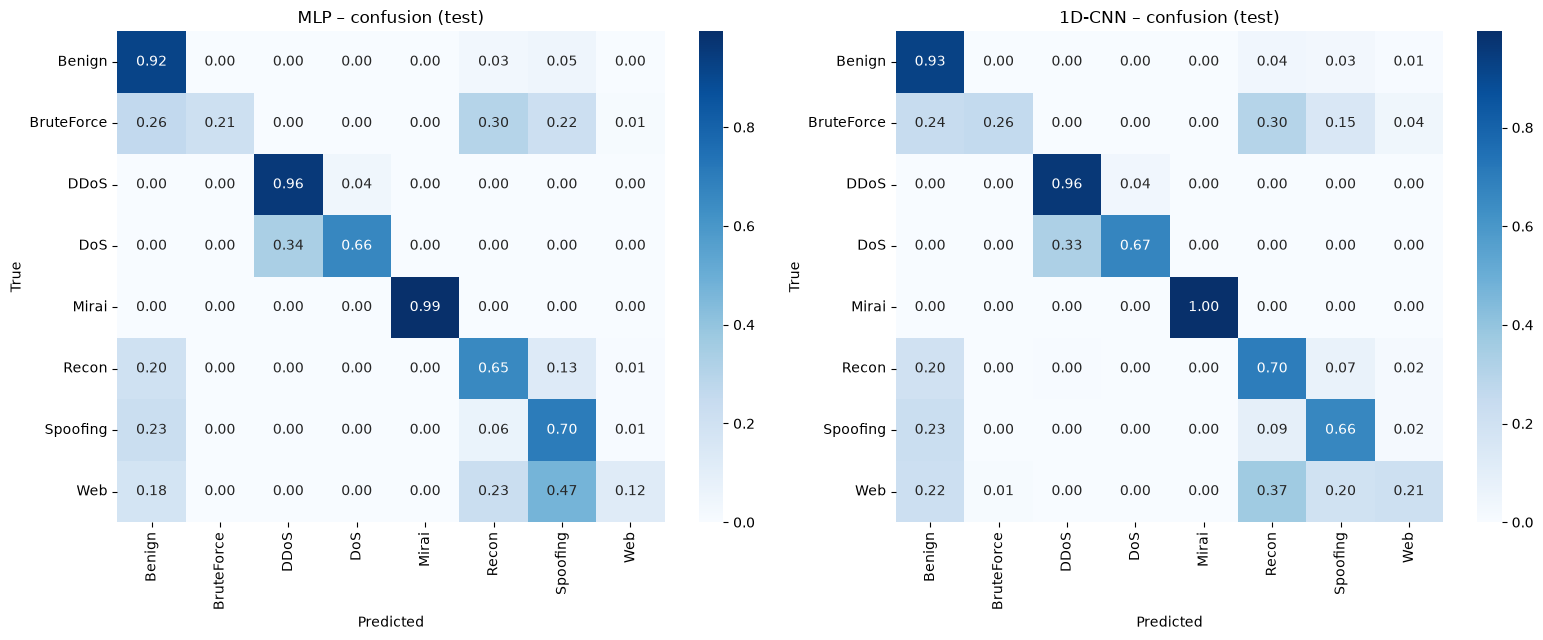

In [20]:
# Normalised confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (n, (pred, _)) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred, labels=np.arange(n_classes), normalize="true")
    sns.heatmap(cm, annot=n_classes <= 10, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax)
    ax.set_title(f"{n} – confusion (test)"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout();  plt.show()